# Lab L4-3：生成的圖必須是「我們的」產品——IP-Adapter vs DreamBooth-LoRA（D4-3）

**需求單 #D4-3**（虛構公司：曜嶼電子，品牌部）：生成的圖必須是我們的產品、品牌一致的風格。提示詞描述不出產品外觀，每次都不一樣。

| 部分 | 做什麼 | 輸出 |
|---|---|---|
| 0 | 產品照：6 張同一個背包（代替「學員自己拍的照片」） | 訓練圖網格 |
| 1 | 基準：只用提示詞 | 「像不像我們的背包」 |
| 2 | 不訓練：IP-Adapter 給一張參考照 | 參考照 → 新場景 |
| 3 | LoRA 的參數量：W ＋ B·A | 參數表 |
| 4 | 訓練：DreamBooth ＋ LoRA（`sks backpack`），T4 的省記憶體設定 | 損失、時間、VRAM |
| 5 | 驗收：前後對照網格；有沒有「背下」訓練照（過度擬合） | 對照網格、最近訓練圖相似度 |

**照片授權**：Google DreamBooth 資料集的 `backpack`（Unsplash 授權，攝影 @laurachouette；`references_and_licenses.txt`）。
換成你自己的產品照：把 6～10 張照片放進 `my_photos/`，把 `PHOTO_DIR` 改成 `"my_photos"`。**只用你有權使用的照片。**

In [24]:
# 第 1 格：環境
%pip install -q -U diffusers transformers accelerate peft
%pip uninstall -y -q torchao   # Colab 預裝的 torchao 太舊，peft 會拒絕（ImportError）；本實驗用不到
import torch, time, platform, gc, os, glob, random, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import diffusers, peft
import glob, subprocess
from matplotlib import font_manager
# Colab 預設沒有中文字型：安裝 Noto CJK，否則圖上的中文會變成方框（D1-2 同樣做法）
NOTO = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if not glob.glob(NOTO) and platform.system() == "Linux":
    subprocess.run("apt-get -qq install -y fonts-noto-cjk > /dev/null", shell=True)
for f in glob.glob(NOTO):
    font_manager.fontManager.addfont(f)
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=f).get_name()
print("torch", torch.__version__, "| diffusers", diffusers.__version__, "| peft", peft.__version__, "| python", platform.python_version())
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
if device == "cuda":
    free, total = torch.cuda.mem_get_info()
    print("GPU:", torch.cuda.get_device_name(0), f"| 可用 VRAM {free/1e9:.1f} / {total/1e9:.1f} GB")
SEED = 0            # 生成用的 seed：想和隔壁同學比較時，改成你的座號
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
STEPS = 400      # LoRA 訓練步數（沒有 GPU：不要訓練，直接看講師的輸出）
RANK = 4         # LoRA 的秩 r

def show_row(imgs, titles, size=2.8, path=None):
    fig, axes = plt.subplots(1, len(imgs), figsize=(size * len(imgs), size + 0.5))
    for ax, im, t in zip(np.atleast_1d(axes), imgs, titles):
        ax.imshow(im); ax.set_title(t, fontsize=9); ax.axis("off")
    plt.tight_layout()
    if path: plt.savefig(path, dpi=100)
    plt.show()

def vram():
    return f"{torch.cuda.max_memory_allocated()/1e9:.2f} GB" if device == "cuda" else "（CPU）"

torch 2.14.1+cu130 | diffusers 0.43.0 | peft 0.21.2 | python 3.13.16
GPU: Tesla T4 | 可用 VRAM 8.0 / 15.6 GB


## 0. 產品照

6 張產品照，每張 (512, 512)


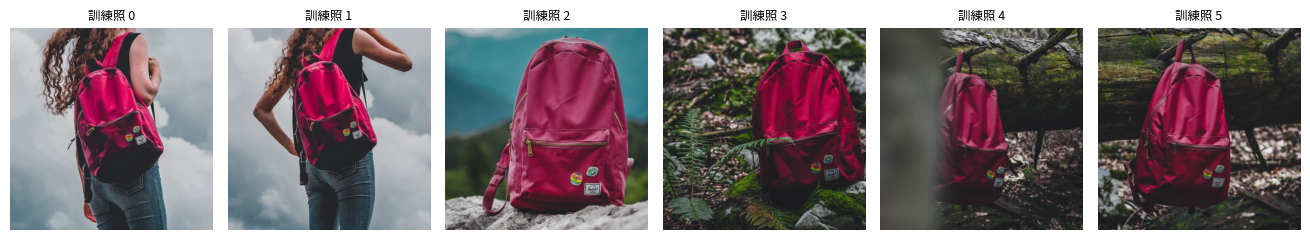

In [25]:
PHOTO_DIR = "data/download/backpack"
if not os.path.isdir(PHOTO_DIR):
    os.makedirs(PHOTO_DIR)
    for i in range(6):
        url = f"https://raw.githubusercontent.com/google/dreambooth/main/dataset/backpack/{i:02d}.jpg"
        urllib.request.urlretrieve(url, f"{PHOTO_DIR}/{i:02d}.jpg")

def center_square(im, size=512):
    w, h = im.size; s = min(w, h)
    return im.crop(((w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2)).resize((size, size), Image.BICUBIC)

photos = [center_square(Image.open(p).convert("RGB")) for p in sorted(glob.glob(f"{PHOTO_DIR}/*.*"))]
print(len(photos), "張產品照，每張", photos[0].size)
show_row(photos, [f"訓練照 {i}" for i in range(len(photos))], size=2.2, path="train_photos.png")

## 1. 基準：只用提示詞
用盡力描述的提示詞，生成 4 張。和上面的產品照比：顏色、口袋、小徽章、背帶一樣嗎？

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


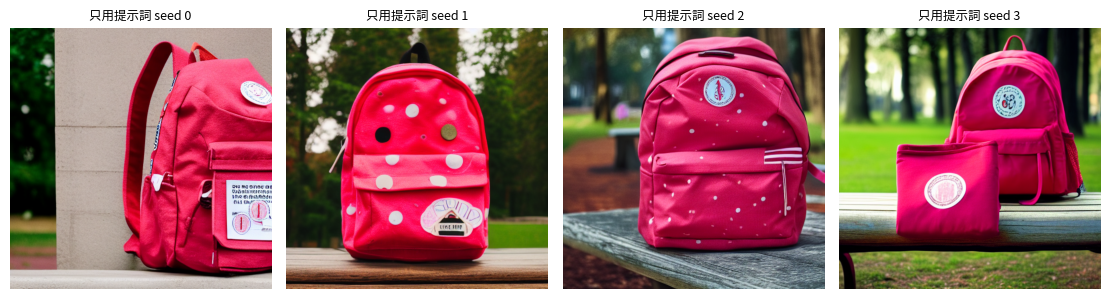

In [26]:
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
pipe = StableDiffusionPipeline.from_pretrained(MODEL, torch_dtype=dtype, safety_checker=None).to(device)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)

DESC = "a photo of a pinkish-red backpack with small round patches on the front pocket, on a wooden bench in a park"
gens = lambda prompt, n=4, **kw: pipe([prompt] * n, num_inference_steps=25, guidance_scale=7.5,
                                      generator=[torch.Generator(device).manual_seed(s) for s in range(n)], **kw).images
base = gens(DESC)
show_row(base, [f"只用提示詞 seed {s}" for s in range(4)], path="prompt_only.png")

## 2. 不訓練：IP-Adapter
把一張參考照經過 CLIP 的**影像**編碼器變成向量，用另一組交叉注意力接進 U-Net（文字那一組不動）。
`scale` 決定參考照的份量：0＝只聽文字，1＝幾乎照抄參考照。

Loading weights:   0%|          | 0/520 [00:00<?, ?it/s]

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


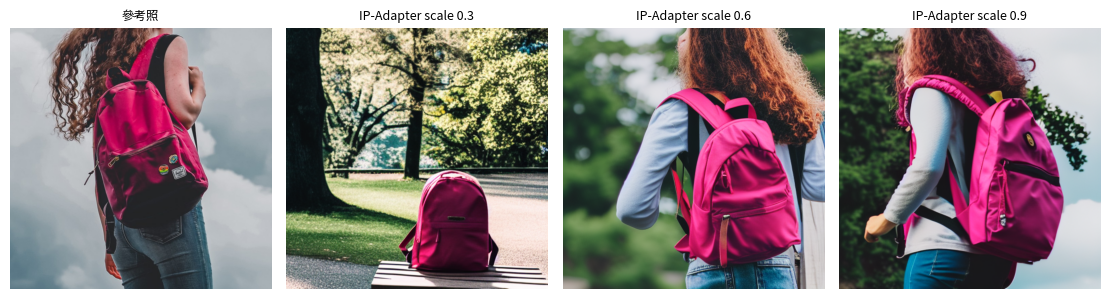

In [27]:
pipe.load_ip_adapter("h94/IP-Adapter", subfolder="models", weight_name="ip-adapter_sd15.bin")
SCENE = "a backpack on a wooden bench in a park, sunny day"
ref = photos[0]
ipa = {}
for sc in [0.3, 0.6, 0.9]:
    pipe.set_ip_adapter_scale(sc)
    ipa[sc] = pipe(SCENE, ip_adapter_image=ref, num_inference_steps=25, guidance_scale=7.5,
                   generator=torch.Generator(device).manual_seed(SEED)).images[0]
show_row([ref] + list(ipa.values()), ["參考照"] + [f"IP-Adapter scale {sc}" for sc in ipa], path="ip_adapter.png")
pipe.unload_ip_adapter()

## 3. LoRA：凍結 W，只學一對很細的矩陣
原本一層的輸出 ＝ W·x。LoRA 改成 W·x ＋ B·(A·x)：W 不動（凍結），只訓練 A（r × d）和 B（d × r）。

一個 768 × 768 的層：全部微調要學 768 × 768 ＝ 589,824 個數字；r ＝ 4 的 LoRA 只學 2 × 768 × 4 ＝ 6,144 個。

In [28]:
d = 768
for r in [4, 8, 16]:
    print(f"r＝{r:2d}：LoRA {2*d*r:>7,} 個參數，是全部的 {2*d*r/(d*d):.2%}")

r＝ 4：LoRA   6,144 個參數，是全部的 1.04%
r＝ 8：LoRA  12,288 個參數，是全部的 2.08%
r＝16：LoRA  24,576 個參數，是全部的 4.17%


加 LoRA 之前，先用原本的 SD1.5 畫一張「對照組」：之後關掉 LoRA 時，應該和這張一模一樣（稽核用）。

In [29]:
ORIG_PROMPT = "a photo of sks backpack on a wooden bench in a park"
orig = pipe(ORIG_PROMPT, num_inference_steps=25, guidance_scale=7.5, generator=torch.Generator(device).manual_seed(SEED)).images[0]

from peft import LoraConfig
unet = pipe.unet
unet.requires_grad_(False); pipe.vae.requires_grad_(False); pipe.text_encoder.requires_grad_(False)
total = sum(p.numel() for p in unet.parameters())
lora_cfg = LoraConfig(r=RANK, lora_alpha=RANK, init_lora_weights="gaussian",
                      target_modules=["to_q", "to_k", "to_v", "to_out.0"])
unet.add_adapter(lora_cfg)
trainable = [p for p in unet.parameters() if p.requires_grad]
n_train = sum(p.numel() for p in trainable)
print(f"U-Net 全部 {total/1e6:.0f}M 個參數；LoRA 要訓練 {n_train:,} 個（{n_train/total:.2%}）")

U-Net 全部 860M 個參數；LoRA 要訓練 797,184 個（0.09%）


## 4. 訓練：DreamBooth ＋ LoRA
**DreamBooth**：用一個罕見的字 `sks` 當產品的名字，提示詞固定是「a photo of sks backpack」。
模型學的是「sks 這個字＝這個背包」；「backpack」這個類別詞讓它從已經會畫的背包出發。

訓練迴圈就是 D3-3 的「預測雜訊」：加雜訊 → U-Net 預測雜訊 → MSE。差別：在潛在空間（D2-3 的 VAE）、只更新 LoRA。

T4 的省記憶體設定：fp16 混合精度、梯度檢查點（gradient checkpointing）、一次一張圖。

In [30]:
from diffusers import DDPMScheduler
from diffusers.training_utils import cast_training_params
noise_sched = DDPMScheduler.from_pretrained(MODEL, subfolder="scheduler")
INSTANCE = "a photo of sks backpack"

with torch.no_grad():
    # 先把照片都編碼成潛在（含左右翻轉），訓練時不用再跑 VAE 編碼器
    px = torch.stack([torch.from_numpy(np.asarray(im)).permute(2, 0, 1) for im in photos]).float() / 127.5 - 1
    px = torch.cat([px, px.flip(-1)])
    latents = torch.cat([pipe.vae.encode(px[i:i+2].to(device, dtype)).latent_dist.sample() for i in range(0, len(px), 2)])
    latents = latents * pipe.vae.config.scaling_factor
    ids = pipe.tokenizer(INSTANCE, padding="max_length", max_length=pipe.tokenizer.model_max_length, return_tensors="pt").input_ids
    text_emb = pipe.text_encoder(ids.to(device))[0]
print("潛在", tuple(latents.shape), "| 文字向量", tuple(text_emb.shape))

cast_training_params(unet, dtype=torch.float32)        # 只有 LoRA 參數用 fp32 訓練，其餘維持 fp16
unet.enable_gradient_checkpointing()
unet.train()
opt = torch.optim.AdamW([p for p in unet.parameters() if p.requires_grad], lr=1e-4)
scaler = torch.amp.GradScaler("cuda", enabled=device == "cuda")   # fp16 的小梯度可能變成 0：先放大再縮回（D4-1 也用過）
if device == "cuda":
    torch.cuda.reset_peak_memory_stats()
losses, t0 = [], time.time()
for step in range(STEPS):
    x0 = latents[torch.randint(0, len(latents), (1,))]
    noise = torch.randn_like(x0)
    t = torch.randint(0, noise_sched.config.num_train_timesteps, (1,), device=device)
    xt = noise_sched.add_noise(x0, noise, t)
    with torch.autocast(device_type=device, dtype=torch.float16, enabled=device == "cuda"):
        pred = unet(xt, t, encoder_hidden_states=text_emb).sample
    loss = torch.nn.functional.mse_loss(pred.float(), noise.float())   # 預測雜訊（D3-3）
    opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    losses.append(loss.item())
    if (step + 1) % 100 == 0:
        print(f"step {step+1}/{STEPS} | 最近 100 步平均 loss {np.mean(losses[-100:]):.4f} | {time.time()-t0:.0f}s")
print(f"訓練 {time.time()-t0:.0f}s | VRAM 峰值 {vram()}")
unet.eval(); unet.disable_gradient_checkpointing()
b_norm = sum(p.norm().item() for n, p in unet.named_parameters() if "lora_B" in n)
print(f"所有 lora_B 的範數加總 {b_norm:.3f}（訓練前是 0；還是 0 代表沒學到東西）")

from peft.utils import get_peft_model_state_dict
from diffusers.utils import convert_state_dict_to_diffusers
StableDiffusionPipeline.save_lora_weights("lora_sks_backpack", unet_lora_layers=convert_state_dict_to_diffusers(get_peft_model_state_dict(unet)))
print("LoRA 檔案大小", f"{os.path.getsize('lora_sks_backpack/pytorch_lora_weights.safetensors')/1e6:.1f} MB")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


潛在 (12, 4, 64, 64) | 文字向量 (1, 77, 768)
step 100/400 | 最近 100 步平均 loss 0.1325 | 44s
step 200/400 | 最近 100 步平均 loss 0.1598 | 88s
step 300/400 | 最近 100 步平均 loss 0.1962 | 131s
step 400/400 | 最近 100 步平均 loss 0.1067 | 174s
訓練 174s | VRAM 峰值 6.98 GB
所有 lora_B 的範數加總 20.816（訓練前是 0；還是 0 代表沒學到東西）
LoRA 檔案大小 3.2 MB


## 5. 驗收
### 5a. 前後對照：同一個 seed，關掉／打開 LoRA

稽核：LoRA 關掉後 vs 加 LoRA 前，最大像素差 0（0 或很小＝原本的 U-Net 沒被改）


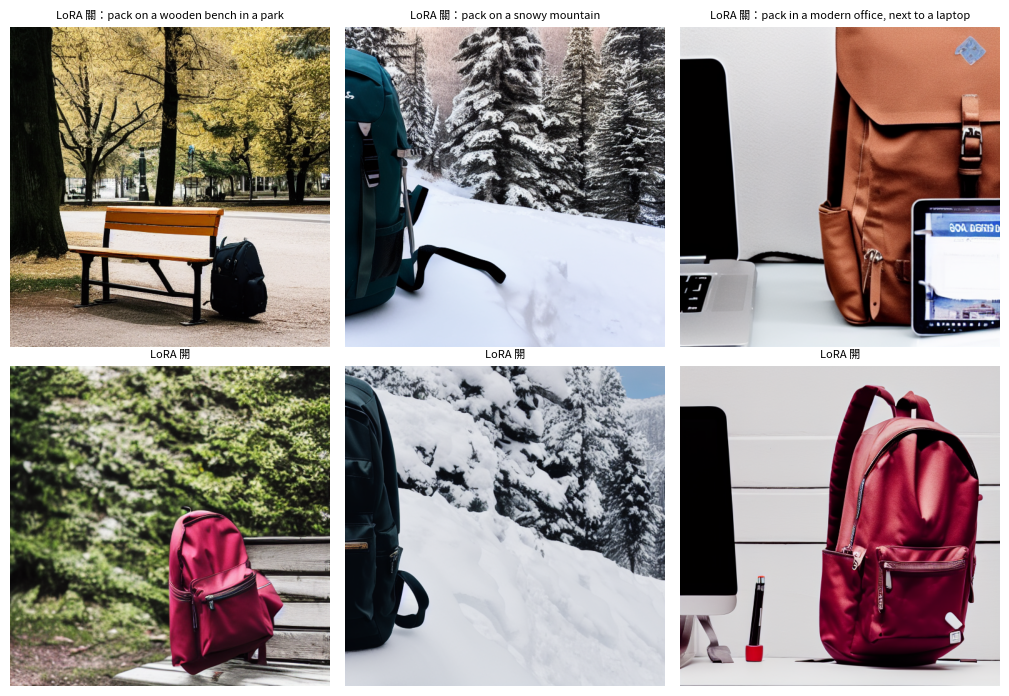

In [31]:
PROMPTS = ["a photo of sks backpack on a wooden bench in a park",
           "a photo of sks backpack on a snowy mountain",
           "a photo of sks backpack in a modern office, next to a laptop"]
rows = []
for p in PROMPTS:
    unet.disable_adapters(); before = pipe(p, num_inference_steps=25, guidance_scale=7.5, generator=torch.Generator(device).manual_seed(SEED)).images[0]
    unet.enable_adapters();  after = pipe(p, num_inference_steps=25, guidance_scale=7.5, generator=torch.Generator(device).manual_seed(SEED)).images[0]
    rows.append((before, after))
unet.disable_adapters()
same = pipe(ORIG_PROMPT, num_inference_steps=25, guidance_scale=7.5, generator=torch.Generator(device).manual_seed(SEED)).images[0]
unet.enable_adapters()
diff = np.abs(np.asarray(same).astype(int) - np.asarray(orig).astype(int)).max()
print(f"稽核：LoRA 關掉後 vs 加 LoRA 前，最大像素差 {diff}（0 或很小＝原本的 U-Net 沒被改）")
fig, axes = plt.subplots(2, len(PROMPTS), figsize=(3.4 * len(PROMPTS), 7))
for j, (b, a) in enumerate(rows):
    axes[0, j].imshow(b); axes[0, j].axis("off"); axes[0, j].set_title("LoRA 關：" + PROMPTS[j][19:], fontsize=8)
    axes[1, j].imshow(a); axes[1, j].axis("off"); axes[1, j].set_title("LoRA 開", fontsize=8)
plt.tight_layout(); plt.savefig("lora_before_after.png", dpi=100); plt.show()

### 5b. 過度擬合：是不是「背下」了訓練照？
每張生成圖和 6 張訓練照比 CLIP **影像**相似度，取最大值。
接近 1 → 幾乎是某一張訓練照（姿勢、背景都一樣）＝背下來了；產品像、但場景不同，才是我們要的。
參考線：訓練照彼此之間（每張和「其他張裡最像的」比）。生成圖比這條線還高，就要懷疑背下來了。

In [32]:
from transformers import CLIPModel, CLIPProcessor
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

@torch.no_grad()
def img_emb(ims):
    px = proc(images=ims, return_tensors="pt").pixel_values.to(device)
    e = clip.visual_projection(clip.vision_model(pixel_values=px).pooler_output)   # 影像 → 512 維
    return e / e.norm(dim=-1, keepdim=True)

E_train = img_emb(photos)
for name, ims in [("只用提示詞", base), ("LoRA 開", [a for _, a in rows]), ("LoRA 關", [b for b, _ in rows])]:
    sims = (img_emb(ims) @ E_train.T).max(dim=1).values
    print(f"{name:6s}：和最像的訓練照相似度 {sims.mean():.3f}（每張：{', '.join(f'{v:.2f}' for v in sims.tolist())}）")
# 參考線：每張訓練照和「其他 5 張裡最像的那張」比，再平均（同樣取最大值，才公平）
tt = E_train @ E_train.T
tt.fill_diagonal_(-1)
loo = tt.max(dim=1).values.mean().item()
print(f"參考線：訓練照和其他訓練照中最像的那張，平均相似度 {loo:.3f}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

只用提示詞 ：和最像的訓練照相似度 0.839（每張：0.81, 0.87, 0.86, 0.81）
LoRA 開：和最像的訓練照相似度 0.857（每張：0.89, 0.85, 0.84）
LoRA 關：和最像的訓練照相似度 0.785（每張：0.77, 0.82, 0.76）
參考線：訓練照和其他訓練照中最像的那張，平均相似度 0.954


## 6. 延伸（選做）
1. 把 `STEPS` 改成 1200 重新訓練：場景還換得過去嗎？「和最像的訓練照相似度」怎麼變？（過度擬合）
2. 把 `RANK` 改成 16：LoRA 檔案多大？效果有差嗎？
3. 換成你自己的產品照（6～10 張、不同角度、不同背景）。